# Trying to Improve Our Model

* Our final model (Logistic Regression) reached 67.6% accuracy.
* In this notebook we try a few ideas to improve it: using fewer features, handling the outliers, trying other models and balancing the classes.
* We use the same data and the same train-test split as our final notebook, so the results can be compared.

#  1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

#  2.Load and Prepare the Data

In [2]:
# Same cleaning and features as our final notebook
df = pd.read_csv("dataset/data.csv")
df = df.dropna(subset=["shot_made_flag"])

df["home"] = df["matchup"].str.contains("vs.", regex=False).astype(int)
df["season_start"] = df["season"].str[:4].astype(int)
df["time_remaining"] = df["minutes_remaining"] * 60 + df["seconds_remaining"]

numeric_features = ["loc_x", "loc_y", "shot_distance", "time_remaining",
                    "period", "playoffs", "home", "season_start"]

categorical_features = ["action_type", "combined_shot_type", "shot_type",
                        "shot_zone_area", "shot_zone_basic", "shot_zone_range", "opponent"]

X = df[numeric_features + categorical_features]
y = df["shot_made_flag"].astype(int)

# Same split as our final notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (20557, 15)
Testing set : (5140, 15)


#  3.Helper Function

In [3]:
results = []

# Train a model with the given features and save its accuracy and F1 score on the test set
def try_model(name, model, numeric, categorical, X_tr=None, X_te=None):
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te

    pipeline = Pipeline([
        ("preprocessor", ColumnTransformer([
            ("num", StandardScaler(), numeric),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
        ])),
        ("model", model)
    ])
    pipeline.fit(X_tr[numeric + categorical], y_train)
    y_pred = pipeline.predict(X_te[numeric + categorical])

    accuracy = accuracy_score(y_test, y_pred)
    results.append({"Experiment": name, "Accuracy": accuracy, "F1 Score": f1_score(y_test, y_pred)})
    print(f"{name}: accuracy = {accuracy:.4f}")

#  4.Our Final Model

In [4]:
try_model("Logistic Regression (final model)", LogisticRegression(C=0.1, max_iter=2000),
          numeric_features, categorical_features)

Logistic Regression (final model): accuracy = 0.6763


* This is our final model with 67.6% accuracy. We compare every experiment with this number.

#  5.Experiment 1: Fewer Features

* In the EDA, shot distance and shot type had the strongest relationship with the outcome. Maybe the other features only add noise.

In [5]:
few_numeric = ["shot_distance"]
few_categorical = ["action_type", "combined_shot_type"]

try_model("Logistic Regression (fewer features)", LogisticRegression(C=0.1, max_iter=2000),
          few_numeric, few_categorical)

try_model("KNN (all features)", KNeighborsClassifier(n_neighbors=75, weights="distance", p=1),
          numeric_features, categorical_features)

try_model("KNN (fewer features)", KNeighborsClassifier(n_neighbors=75, weights="distance", p=1),
          few_numeric, few_categorical)

Logistic Regression (fewer features): accuracy = 0.6755


KNN (all features): accuracy = 0.6576


KNN (fewer features): accuracy = 0.6735


* Logistic Regression stays the same with fewer features (67.6%), so the extra features do not hurt it.
* KNN improves a lot, from 65.8% to 67.4%, because extra features make the distances between shots less meaningful.
* Still, no version is better than our final model.

#  6.Experiment 2: Handling the Outliers

* The IQR method found 68 shots farther than 45 feet (backcourt shots). Here we cap them at 45 feet to see if they affect the model.

In [6]:
# Replace every distance above 45 feet with 45
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()
X_train_capped["shot_distance"] = X_train_capped["shot_distance"].clip(upper=45)
X_test_capped["shot_distance"] = X_test_capped["shot_distance"].clip(upper=45)

try_model("Logistic Regression (outliers capped)", LogisticRegression(C=0.1, max_iter=2000),
          numeric_features, categorical_features, X_train_capped, X_test_capped)

try_model("KNN (outliers capped)", KNeighborsClassifier(n_neighbors=75, weights="distance", p=1),
          numeric_features, categorical_features, X_train_capped, X_test_capped)

Logistic Regression (outliers capped): accuracy = 0.6765


KNN (outliers capped): accuracy = 0.6576


* Capping the outliers gives 67.7% for Logistic Regression and 65.8% for KNN, the same as before.
* The 68 backcourt shots do not affect either model, so keeping them was fine.

#  7.Experiment 3: Other Models

* Maybe Logistic Regression is too simple. We try two stronger models that can learn more complex patterns.

In [7]:
# Random Forest: many decision trees that vote together
try_model("Random Forest", RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
          numeric_features, categorical_features)

# XGBoost: trees built one after another, each one fixing the mistakes of the previous ones
try_model("XGBoost", XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=3, random_state=42),
          numeric_features, categorical_features)

Random Forest: accuracy = 0.6767


XGBoost: accuracy = 0.6761


* Random Forest (67.7%) and XGBoost (67.6%) give the same accuracy as Logistic Regression.
* Even stronger models cannot find more patterns, so the model is not the problem.

#  8.Experiment 4: Balanced Classes

* Only 45% of the shots are made. Here we give the made shots more weight during training.
* This experiment is only for Logistic Regression: KNN has no class weights, because it does not learn weights, it only looks at the nearest shots.

In [8]:
try_model("Logistic Regression (balanced classes)", LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced"),
          numeric_features, categorical_features)

Logistic Regression (balanced classes): accuracy = 0.6745


* The model finds a few more made shots (higher F1 score), but the accuracy drops slightly to 67.5%.

#  9.Comparison

In [9]:
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)

display(results_df.round(4).reset_index(drop=True))

,Experiment,Accuracy,F1 Score
0,Random Forest,0.6767,0.5584
1,Logistic Regression (outliers capped),0.6765,0.5592
2,Logistic Regression (final model),0.6763,0.5591
3,XGBoost,0.6761,0.5587
4,Logistic Regression (fewer features),0.6755,0.5597
5,Logistic Regression (balanced classes),0.6745,0.5638
6,KNN (fewer features),0.6735,0.5445
7,KNN (all features),0.6576,0.4827
8,KNN (outliers capped),0.6576,0.4827


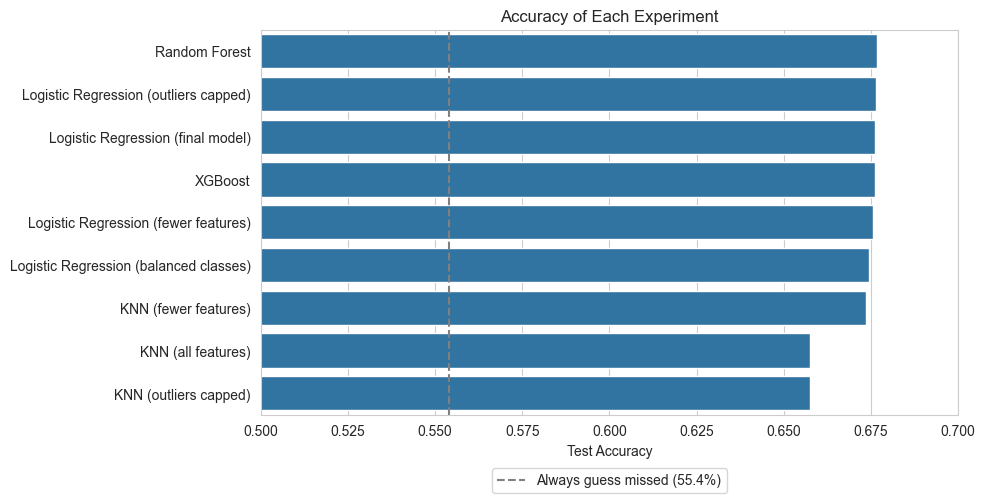

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(data=results_df, y="Experiment", x="Accuracy", color="tab:blue")

plt.axvline(0.554, color="gray", linestyle="--", label="Always guess missed (55.4%)")

plt.title("Accuracy of Each Experiment")
plt.xlabel("Test Accuracy")
plt.ylabel("")
plt.xlim(0.5, 0.7)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))

plt.show()

* All experiments are between 67.4% and 67.7%, except KNN with all features (65.8%, with or without capping the outliers).
* The differences are very small (less than 0.3%), so none of the ideas really improved the model.

#  10.Conclusion

* We tried fewer features, handling the outliers, two stronger models and balanced classes, and the accuracy stayed at about 68%.
* This shows the limit comes from the data, not from our choices: the same shot from the same spot sometimes goes in and sometimes not, and the data has no information about the defender or fatigue.
* We keep Logistic Regression as our final model, because it is as accurate as the stronger models, faster, and easier to explain.